
# Classificazione di masse mammarie mediante Machine Learning

**Corso:** Apprendimento Automatico e Apprendimento Profondo

**Dataset:** Breast Cancer Wisconsin (Diagnostic) — UCI Machine Learning Repository

## 1. Introduzione

L'obiettivo del progetto è sviluppare e confrontare diversi algoritmi di classificazione supervisionata per distinguere campioni benigni e maligni sulla base di caratteristiche numeriche estratte da immagini di nuclei cellulari.

Il progetto comprende l'analisi delle feature mediante PCA, l'addestramento di tre classificatori, la valutazione delle prestazioni e l'interpretazione dei risultati attraverso SHAP.



## 2. Descrizione del dataset

Il dataset Breast Cancer Wisconsin (Diagnostic) proviene dalla UCI Machine Learning Repository.

Contiene 569 osservazioni, ciascuna descritta da 30 caratteristiche numeriche ricavate dall'analisi di immagini digitalizzate di nuclei cellulari.

La variabile target rappresenta due possibili diagnosi:
- B: benigno (357 campioni)
- M: maligno (212 campioni)

L'obiettivo è sviluppare un sistema di classificazione supervisionata capace di distinguere le due classi.

L'analisi preliminare ha confermato l'assenza di valori mancanti.

Fonte: https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

# Crea la cartella risultati se non esiste.
# Non genera errori se la cartella esiste già, grazie a exist_ok=True.
# Permette di salvare correttamente grafici e file CSV.
Path("risultati").mkdir(parents=True, exist_ok=True)

print("Ambiente Python configurato correttamente!")


Ambiente Python configurato correttamente!


In [2]:

# Percorso del dataset
percorso = Path("dataset/wdbc.data")

# Lettura del file senza intestazioni
df = pd.read_csv(percorso, header=None)

# Visualizziamo dimensioni e prime 5 righe
print("Dimensioni del dataset:", df.shape)

display(df.head())


Dimensioni del dataset: (569, 32)


,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:

# Le 10 caratteristiche di base del dataset
caratteristiche = [
    "radius", "texture", "perimeter", "area",
    "smoothness", "compactness", "concavity",
    "concave_points", "symmetry", "fractal_dimension"
]

# Ogni caratteristica viene misurata in 3 modi
colonne_feature = (
    [f"mean_{x}" for x in caratteristiche] +
    [f"se_{x}" for x in caratteristiche] +
    [f"worst_{x}" for x in caratteristiche]
)

# Assegniamo i nomi alle 32 colonne
df.columns = ["id", "diagnosis"] + colonne_feature

display(df.head())


,id,diagnosis,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean_concavity,mean_concave_points,...,worst_radius,worst_texture,worst_perimeter,worst_area,worst_smoothness,worst_compactness,worst_concavity,worst_concave_points,worst_symmetry,worst_fractal_dimension
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [4]:

print("Dimensioni:", df.shape)

print("\nValori mancanti:")
print(df.isnull().sum().sum())

print("\nDistribuzione delle diagnosi:")
print(df["diagnosis"].value_counts())

print("\nTipi di dati:")
print(df.dtypes.value_counts())


Dimensioni: (569, 32)

Valori mancanti:
0

Distribuzione delle diagnosi:
diagnosis
B    357
M    212
Name: count, dtype: int64

Tipi di dati:
float64    30
int64       1
str         1
Name: count, dtype: int64


In [5]:

# Separazione delle feature e del target

X = df.drop(columns=["id", "diagnosis"])
y = df["diagnosis"].map({"B": 0, "M": 1})

print("Dimensioni X:", X.shape)
print("Dimensioni y:", y.shape)
print("\nDistribuzione del target:")
print(y.value_counts())


Dimensioni X: (569, 30)
Dimensioni y: (569,)

Distribuzione del target:
diagnosis
0    357
1    212
Name: count, dtype: int64



## 3. Preparazione dei dati

L'identificativo del campione viene escluso dalle variabili predittive.

La diagnosi viene convertita in formato numerico:
- 0 = Benigno
- 1 = Maligno

Il dataset viene suddiviso in tre insiemi:
- Training: 60% (341 campioni)
- Validation: 20% (114 campioni)
- Test: 20% (114 campioni)

La suddivisione è stratificata per preservare la distribuzione delle classi e utilizza random_state=42 per garantire la riproducibilità.

La standardizzazione viene eseguita tramite StandardScaler, calcolando media e deviazione standard esclusivamente sul training set.

Questo accorgimento evita il data leakage durante la preparazione dei dati.

In [6]:

# Suddivisione del dataset
# 60% Training - 20% Validation - 20% Test

from sklearn.model_selection import train_test_split

SEED = 42

# Prima suddivisione: 80% sviluppo e 20% test
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

# Seconda suddivisione: 60% training e 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,
    random_state=SEED,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

# Verifica che i tre insiemi siano separati
assert X_train.index.intersection(X_val.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_val.index.intersection(X_test.index).empty

print("\nSuddivisione completata correttamente!")


Training: (341, 30)
Validation: (114, 30)
Test: (114, 30)

Suddivisione completata correttamente!


In [7]:

from sklearn.preprocessing import StandardScaler

# Creazione dello scaler
scaler = StandardScaler()

# Calcoliamo media e deviazione standard SOLO sul training
X_train_scaled = scaler.fit_transform(X_train)

# Applichiamo la stessa trasformazione agli altri dati
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Verifica delle dimensioni
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Test:", X_test_scaled.shape)

print("\nStandardizzazione completata!")


Training: (341, 30)
Validation: (114, 30)
Test: (114, 30)

Standardizzazione completata!



## 4. Analisi delle componenti principali (PCA)

La Principal Component Analysis (PCA) è una tecnica di riduzione della dimensionalità che permette di rappresentare i dati attraverso nuove componenti principali.

L'obiettivo è individuare le direzioni che spiegano la maggiore variabilità delle caratteristiche originali.

La PCA viene calcolata sui dati di training standardizzati.

Vengono prodotti due grafici:
1. Distribuzione dei campioni rispetto alle prime due componenti principali.
2. Varianza spiegata cumulata in funzione del numero di componenti.

L'analisi PCA viene utilizzata a scopo esplorativo. I classificatori successivi sono addestrati sulle 30 feature originali standardizzate.


In [8]:

from sklearn.decomposition import PCA

# Addestriamo la PCA sui dati di training standardizzati
pca = PCA()
pca.fit(X_train_scaled)

# Calcoliamo la varianza spiegata cumulata
varianza_cumulata = np.cumsum(pca.explained_variance_ratio_)

# Numero di componenti necessarie per spiegare il 95% della varianza
n_componenti_95 = np.searchsorted(varianza_cumulata, 0.95) + 1

print("Varianza spiegata dalle prime 2 componenti:",
      round(varianza_cumulata[1] * 100, 2), "%")

print("Componenti necessarie per il 95% della varianza:", n_componenti_95)


Varianza spiegata dalle prime 2 componenti: 63.8 %
Componenti necessarie per il 95% della varianza: 10


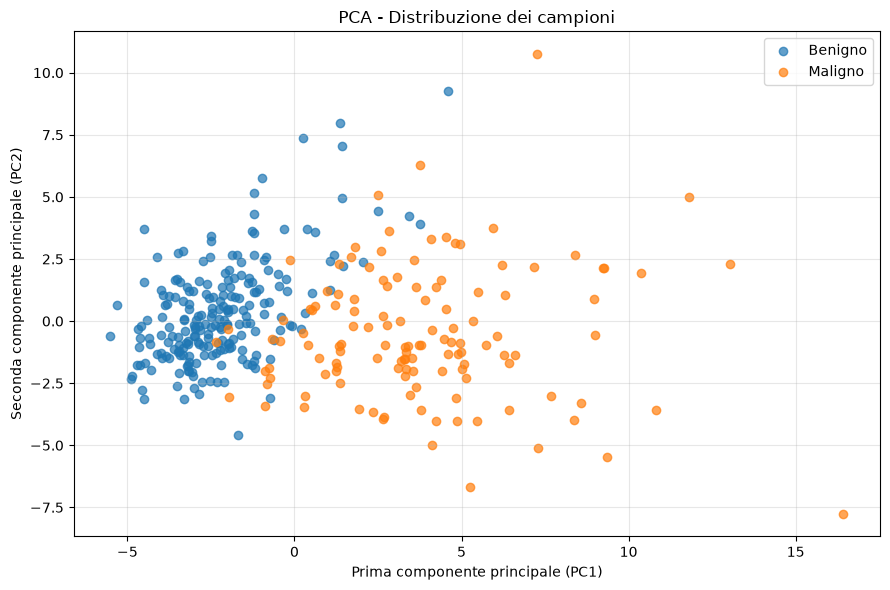

In [9]:

# Proiezione del training sulle prime due componenti
X_pca = pca.transform(X_train_scaled)

# Grafico PCA
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[y_train == 0, 0],
    X_pca[y_train == 0, 1],
    label="Benigno",
    alpha=0.7
)

plt.scatter(
    X_pca[y_train == 1, 0],
    X_pca[y_train == 1, 1],
    label="Maligno",
    alpha=0.7
)

plt.xlabel("Prima componente principale (PC1)")
plt.ylabel("Seconda componente principale (PC2)")
plt.title("PCA - Distribuzione dei campioni")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("risultati/pca_distribuzione.png", dpi=300)
plt.show()


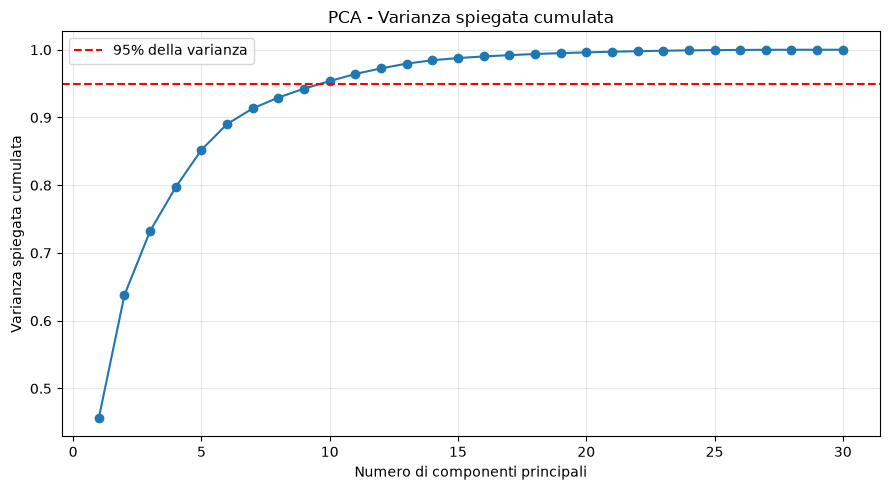

In [10]:

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(varianza_cumulata) + 1),
    varianza_cumulata,
    marker="o"
)

plt.axhline(
    y=0.95,
    color="red",
    linestyle="--",
    label="95% della varianza"
)

plt.xlabel("Numero di componenti principali")
plt.ylabel("Varianza spiegata cumulata")
plt.title("PCA - Varianza spiegata cumulata")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("risultati/pca_varianza.png", dpi=300)
plt.show()



### 4.1 Interpretazione dei risultati PCA

Le prime due componenti principali spiegano circa il 63,8% della varianza totale presente nei dati di training.

Per conservare almeno il 95% della varianza sono necessarie 10 componenti principali.

La rappresentazione bidimensionale permette di osservare la distribuzione dei campioni benigni e maligni e le eventuali sovrapposizioni tra le due classi.

La PCA evidenzia la possibilità di ridurre la dimensionalità del dataset, ma la conservazione della varianza non garantisce necessariamente la conservazione di tutte le informazioni utili alla classificazione.

In [11]:

# Analisi dei coefficienti della prima componente PCA
loadings = pd.Series(
    pca.components_[0],
    index=X.columns
)

# Selezioniamo le 10 feature con i coefficienti
# più elevati in valore assoluto
top_feature = loadings.abs().nlargest(10).index

tabella_pca = pd.DataFrame({
    "Feature": top_feature,
    "Coefficiente PC1": loadings.loc[top_feature].values
})

display(tabella_pca.round(4))

# Salvataggio dei risultati
tabella_pca.to_csv(
    "risultati/pca_loadings.csv",
    index=False
)


,Feature,Coefficiente PC1
0,mean_concave_points,0.2565
1,mean_concavity,0.2546
2,worst_concave_points,0.2474
3,mean_compactness,0.2386
4,worst_perimeter,0.2357
5,worst_radius,0.2268
6,mean_perimeter,0.2261
7,worst_area,0.2237
8,worst_concavity,0.2209
9,mean_area,0.2205



## 5. Implementazione dei classificatori

Per confrontare differenti tecniche di Machine Learning supervisionato sono stati implementati tre algoritmi:

1. Logistic Regression: classificatore lineare utilizzato come modello di riferimento.
2. Support Vector Machine (SVM): classificatore con kernel RBF, capace di rappresentare separazioni non lineari.
3. Random Forest: metodo ensemble che combina più alberi decisionali.

Tutti i modelli sono addestrati sul medesimo training set standardizzato e valutati sugli stessi campioni.

I parametri utilizzati vengono mantenuti fissi durante il confronto.

L'obiettivo è analizzare le differenze nelle prestazioni dei tre approcci.


In [12]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

# Definizione dei tre classificatori
modelli = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=SEED
    ),
    
    "SVM": SVC(
        kernel="rbf",
        random_state=SEED
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=SEED
    )
}

# Addestramento sui dati di training
for nome, modello in modelli.items():
    modello.fit(X_train_scaled, y_train)
    print(f"{nome}: addestramento completato!")

print("\nTutti i modelli sono stati addestrati!")


Logistic Regression: addestramento completato!
SVM: addestramento completato!
Random Forest: addestramento completato!

Tutti i modelli sono stati addestrati!



## 6. Valutazione dei modelli sulla validation

Le prestazioni dei classificatori vengono confrontate utilizzando cinque metriche:

- Accuracy: proporzione delle classificazioni corrette.
- Precision: proporzione di campioni realmente maligni tra quelli classificati come maligni.
- Recall: capacità di individuare i campioni realmente maligni.
- F1-score: media armonica tra Precision e Recall.
- ROC AUC: capacità del classificatore di distinguere le due classi al variare della soglia decisionale.

Vengono inoltre visualizzate le matrici di confusione e le curve ROC.

Sulla validation, la SVM registra la migliore Accuracy (98,25%) e ROC AUC (99,61%).

La SVM viene quindi individuata come modello preferibile in questa fase, prima della valutazione sul test set.


In [13]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

risultati_validation = []

for nome, modello in modelli.items():
    y_pred = modello.predict(X_val_scaled)

    if hasattr(modello, "decision_function"):
        y_score = modello.decision_function(X_val_scaled)
    else:
        y_score = modello.predict_proba(X_val_scaled)[:, 1]

    risultati_validation.append({
        "Modello": nome,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1-score": f1_score(y_val, y_pred),
        "ROC AUC": roc_auc_score(y_val, y_score)
    })

df_validation = pd.DataFrame(risultati_validation)

display(df_validation.round(4))


,Modello,Accuracy,Precision,Recall,F1-score,ROC AUC
0,Logistic Regression,0.9737,0.9545,0.9767,0.9655,0.9957
1,SVM,0.9825,0.9767,0.9767,0.9767,0.9961
2,Random Forest,0.9737,0.9762,0.9535,0.9647,0.9916


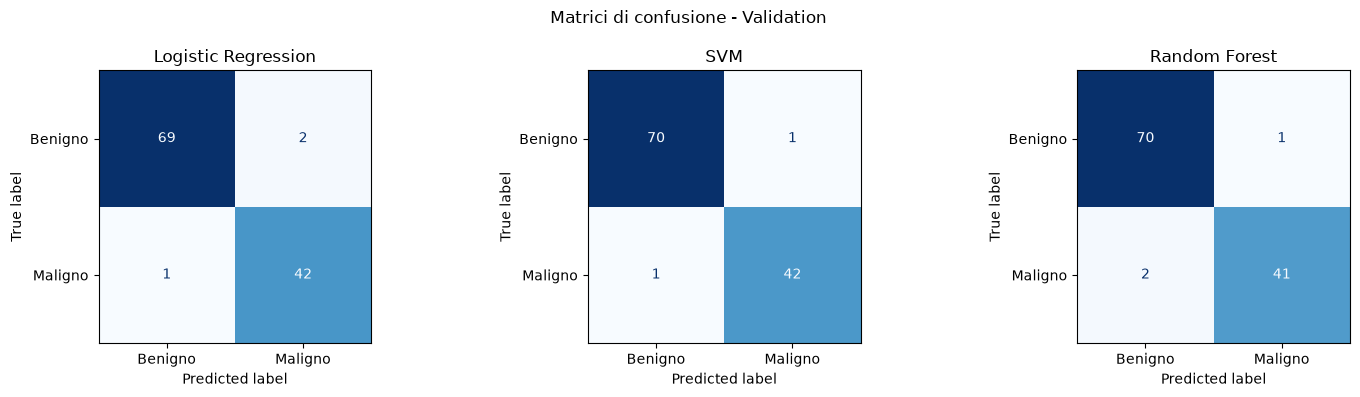

In [14]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nome, modello) in zip(axes, modelli.items()):
    ConfusionMatrixDisplay.from_estimator(
        modello,
        X_val_scaled,
        y_val,
        display_labels=["Benigno", "Maligno"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(nome)

plt.suptitle("Matrici di confusione - Validation")
plt.tight_layout()

plt.savefig(
    "risultati/confusion_matrix_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



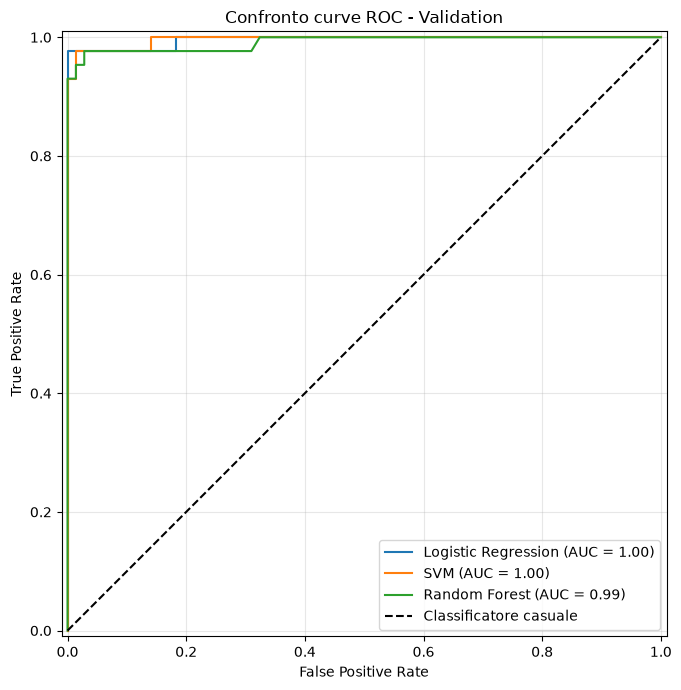

In [15]:

from sklearn.metrics import RocCurveDisplay
import matplotlib.pyplot as plt

# Creiamo il grafico
fig, ax = plt.subplots(figsize=(9, 7))

# Disegniamo la curva ROC di ogni classificatore
for nome, modello in modelli.items():

    RocCurveDisplay.from_estimator(
        modello,
        X_val_scaled,
        y_val,
        name=nome,
        ax=ax
    )

# Linea di riferimento: classificatore casuale
ax.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Classificatore casuale"
)

ax.set_title("Confronto curve ROC - Validation")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

# Salvataggio del grafico
plt.savefig(
    "risultati/roc_curve_validation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



## 7. Valutazione finale sul test set

Il test set contiene 114 campioni non utilizzati durante l'addestramento o il confronto dei modelli sulla validation.

I tre classificatori vengono valutati mediante Accuracy, Precision, Recall, F1-score e ROC AUC.

Logistic Regression e SVM raggiungono entrambe un'Accuracy del 97,37%, mentre Random Forest ottiene il 95,61%.

Random Forest presenta la ROC AUC più elevata, pari a circa 99,70%.

La differenza evidenzia che una ROC AUC maggiore non implica necessariamente una maggiore Accuracy alla soglia decisionale utilizzata.

La valutazione sul test non viene utilizzata per modificare i modelli o selezionare retroattivamente gli iperparametri.


In [16]:

# Valutazione finale dei classificatori sul test set

risultati_test = []

for nome, modello in modelli.items():

    # Predizioni sui dati mai utilizzati nell'addestramento
    y_pred = modello.predict(X_test_scaled)

    # Punteggi per il calcolo della ROC AUC
    if hasattr(modello, "decision_function"):
        y_score = modello.decision_function(X_test_scaled)
    else:
        y_score = modello.predict_proba(X_test_scaled)[:, 1]

    risultati_test.append({
        "Modello": nome,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC AUC": roc_auc_score(y_test, y_score)
    })

# Tabella dei risultati finali
df_test = pd.DataFrame(risultati_test)

display(df_test.round(4))

# Salvataggio per la relazione
df_test.to_csv(
    "risultati/metriche_test.csv",
    index=False
)


,Modello,Accuracy,Precision,Recall,F1-score,ROC AUC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9954
1,SVM,0.9737,0.9756,0.9524,0.9639,0.9940
2,Random Forest,0.9561,0.9744,0.9048,0.9383,0.9970


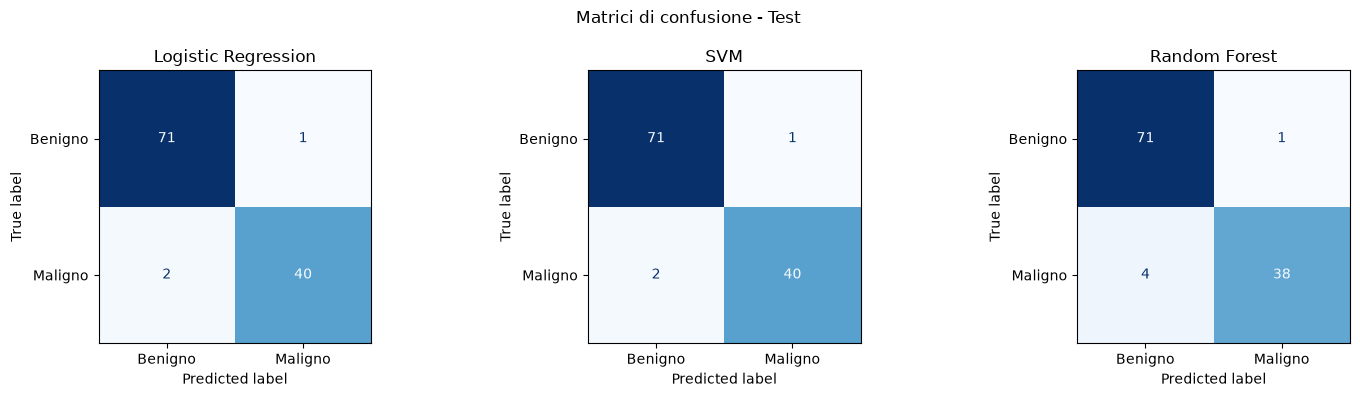

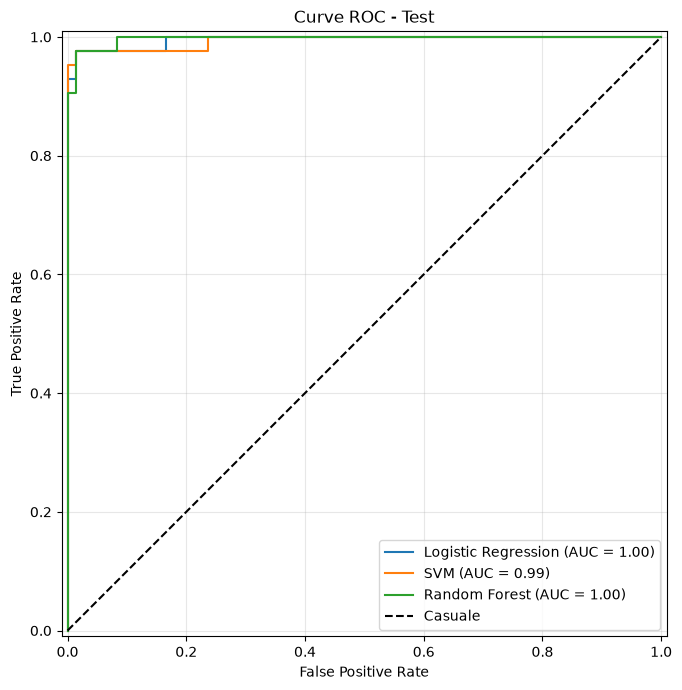

In [17]:

# Matrici di confusione finali
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nome, modello) in zip(axes, modelli.items()):
    ConfusionMatrixDisplay.from_estimator(
        modello,
        X_test_scaled,
        y_test,
        display_labels=["Benigno", "Maligno"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )
    ax.set_title(nome)

plt.suptitle("Matrici di confusione - Test")
plt.tight_layout()
plt.savefig("risultati/confusion_matrix_test.png", dpi=300)
plt.show()

# Curve ROC finali
fig, ax = plt.subplots(figsize=(9, 7))

for nome, modello in modelli.items():
    RocCurveDisplay.from_estimator(
        modello,
        X_test_scaled,
        y_test,
        name=nome,
        ax=ax
    )

ax.plot([0, 1], [0, 1], "k--", label="Casuale")
ax.set_title("Curve ROC - Test")
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("risultati/roc_curve_test.png", dpi=300)
plt.show()



## 8. Interpretabilità mediante SHAP

Per approfondire l'interpretabilità dei modelli viene utilizzato SHAP (SHapley Additive exPlanations).

Questo metodo attribuisce alle caratteristiche un contributo rispetto alle previsioni del modello.

L'analisi viene effettuata sulla Random Forest mediante TreeExplainer.

I valori SHAP vengono calcolati per i 114 campioni del test set, considerando le 30 caratteristiche e le due classi.

Il grafico a barre rappresenta le 15 feature con il maggiore valore SHAP assoluto medio per la classe maligna.

L'importanza SHAP descrive il contributo delle caratteristiche alle previsioni del modello, ma non permette di stabilire relazioni causali.


In [18]:

import shap

# Selezioniamo il modello Random Forest già addestrato
modello_rf = modelli["Random Forest"]

# Creiamo l'explainer SHAP
explainer = shap.TreeExplainer(modello_rf)

# Calcoliamo i valori SHAP sul test set
shap_values = explainer(X_test_scaled)

print("Dimensioni valori SHAP:", shap_values.values.shape)
print("Analisi SHAP completata!")


Dimensioni valori SHAP: (114, 30, 2)
Analisi SHAP completata!


/Users/giorgioanastasio/AAAP_Breast_Cancer/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


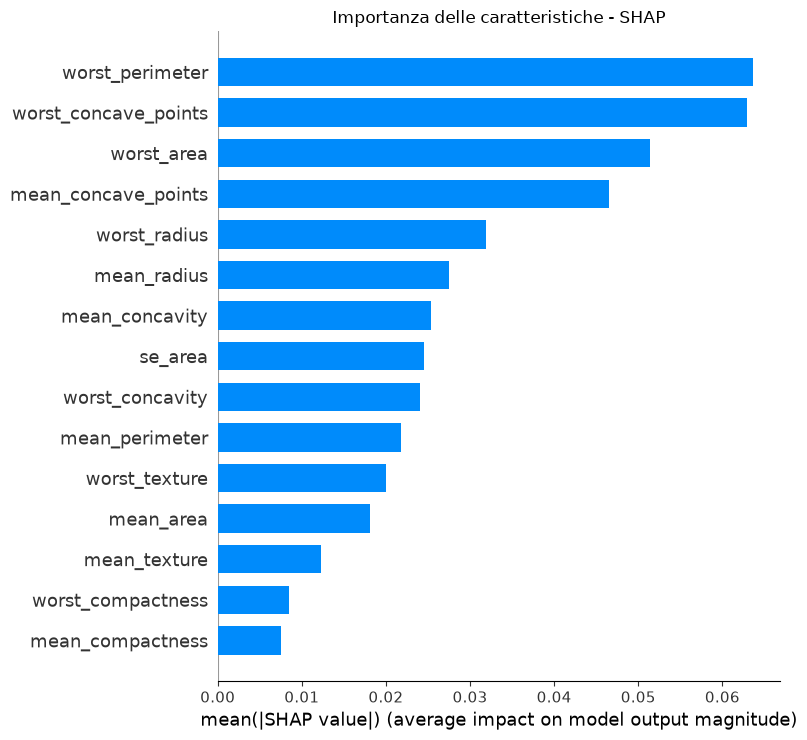

In [19]:

# Selezioniamo i valori SHAP della classe maligna
shap_maligno = shap_values[:, :, 1]

# Grafico dell'importanza delle caratteristiche
shap.summary_plot(
    shap_maligno.values,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title("Importanza delle caratteristiche - SHAP")
plt.tight_layout()

plt.savefig(
    "risultati/shap_importanza.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:

# Visualizzazione dei risultati finali
display(df_test.round(4))

# Verifica dei file generati
from pathlib import Path

for file in sorted(Path("risultati").glob("*")):
    print(file.name)


,Modello,Accuracy,Precision,Recall,F1-score,ROC AUC
0,Logistic Regression,0.9737,0.9756,0.9524,0.9639,0.9954
1,SVM,0.9737,0.9756,0.9524,0.9639,0.9940
2,Random Forest,0.9561,0.9744,0.9048,0.9383,0.9970


confusion_matrix_test.png
confusion_matrix_validation.png
metriche_test.csv
pca_distribuzione.png
pca_loadings.csv
pca_varianza.png
roc_curve_test.png
roc_curve_validation.png
shap_importanza.png



## 9. Conclusioni

Il progetto ha permesso di confrontare tre algoritmi di classificazione supervisionata sul dataset Breast Cancer Wisconsin (Diagnostic).

Tutti i classificatori hanno ottenuto prestazioni elevate sul test set.

Logistic Regression e SVM raggiungono un'Accuracy del 97,37%, mentre Random Forest ottiene il 95,61%.

La PCA ha permesso di analizzare la struttura delle caratteristiche e la varianza spiegata dalle componenti principali.

L'analisi SHAP ha fornito una rappresentazione dell'importanza delle variabili utilizzate dalla Random Forest.

I risultati evidenziano l'efficacia dei modelli sul dataset considerato, ma presentano alcune limitazioni.

In particolare, l'esperimento utilizza una singola suddivisione dei dati, senza validazione esterna. Le prestazioni ottenute non dimostrano l'idoneità dei modelli all'utilizzo clinico.

Il progetto costituisce un esperimento didattico di Machine Learning, non un sistema diagnostico utilizzabile nella pratica medica.
